This Colab-compatible notebook contains the executed local analysis and saved outputs. Dependencies are pinned in the setup cell and source hashes are checked. The saved run used Python 3.14.5; a Colab runtime with a different Python environment may require compatible package changes and may not reproduce bit-for-bit.

## Project charter

**Question:** How well can 11 physicochemical measurements predict the recorded sensory quality score for this UCI red-wine subset?

**Analytical objective:** Predict the recorded panel score as a quasi-continuous proxy, compare a median DummyRegressor baseline with a random forest, and report MAE/RMSE plus score-band errors.

**Proposed screening criteria:** Aggregate test MAE ≤0.65 and extreme-score row recall ≥0.80 for observed scores 3–4 or 8–10. These are analytical thresholds, not a validated business workflow.

**Decision boundary:** This experiment does not validate triage or decision support. Labels are ordinal human judgments; predictions must not be used to reduce sensory review or replace panel decisions.

**Provenance:** [UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine%2Bquality), DOI 10.24432/C56S3T; Kaggle listing: https://www.kaggle.com/competitions/uci-wine-quality-dataset.


The setup pins the package versions used for the saved local run. UCI archive and red-file hashes are asserted before analysis. The notebook was executed locally with Python 3.14.5; Colab runs require network access and a compatible Python runtime.

In [1]:
# Colab-ready setup; rerun this cell if the runtime is reset.
%pip -q install pandas==3.1.0 numpy==2.5.4 scikit-learn==1.9.1 matplotlib==3.11.2 joblib==1.6.0
import hashlib, sklearn
from datetime import datetime, timezone
from IPython.display import display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score, silhouette_score, recall_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold
print("Environment ready", {"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__})


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /private/tmp/crispdm-assignment-venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Environment ready {'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit_learn': '1.9.1'}


In [2]:
import io, zipfile, urllib.request
url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
with urllib.request.urlopen(url, timeout=60) as response:
    archive_bytes = response.read()
retrieved_utc = datetime.now(timezone.utc).isoformat()
archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()
assert archive_sha256 == "3ed56667f4b828242bd732d7d1dd7f2861e54432239d7fa63877014cbb0304d4", "UCI source archive changed; review before relying on saved results"
archive = zipfile.ZipFile(io.BytesIO(archive_bytes))
print(archive.namelist())
csv_bytes = archive.read("winequality-red.csv")
csv_sha256 = hashlib.sha256(csv_bytes).hexdigest()
assert csv_sha256 == "4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e", "UCI source data changed; review before relying on saved results"
df = pd.read_csv(io.BytesIO(csv_bytes), sep=";")
print("retrieved_utc",retrieved_utc,"archive_sha256",archive_sha256,"red_csv_sha256",csv_sha256)
df.head()

['winequality-red.csv', 'winequality-white.csv', 'winequality.names']
retrieved_utc 2026-10-27T03:30:09.065558+00:00 archive_sha256 3ed56667f4b828242bd732d7d1dd7f2861e54432239d7fa63877014cbb0304d4 red_csv_sha256 4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 1. Sample

**Purpose and tasks.** Sample reproducibly; define train, validation, and final test partitions; ensure the sample fits the prediction question.

**Phase intent.** Keep identical predictor signatures together so repeated measurement vectors cannot cross partitions.

**Project-specific decision.** A stratified 10-fold group split assigns folds 0–6 to training, fold 7 to validation, and folds 8–9 to final test. It yields 1,119/160/320 rows and 951/136/272 unique signatures, with zero group overlap.

**Expected evidence.** The saved output reports partition sizes, label proportions, repeated-signature counts, and overlap assertions.

**Independent critique and revision record.** GPT-5.6 review pass 1 identified repeated-vector leakage, ordinal-score interpretation, and unsupported tail-use claims. The revised split groups signatures and reports band/tail metrics. Pass 2 confirmed split integrity and corrected the baseline description; pinned dependencies and source-hash assertions were added. Pass 3 found residual “triage” wording and handoff/template text; these are now removed, and the charter states the model is not validated for decision support.


In [3]:
target = "quality"
assert df[target].between(0, 10).all() and df.isna().sum().sum() == 0
X, y = df.drop(columns=target), df[target]
# Conservatively treat identical predictor vectors as the same sampling group; verify they never disagree on label.
groups = pd.util.hash_pandas_object(X,index=False).astype(str)
group_quality_counts = pd.DataFrame({"signature":groups,"quality":y}).groupby("signature").quality.nunique()
assert group_quality_counts.max() == 1
print("rows",len(df),"unique predictor groups",groups.nunique(),"rows duplicated after first signature",int(X.duplicated().sum()),"rows in repeated groups",int(groups.map(groups.value_counts()).gt(1).sum()))
# Approximate stratification by quality while keeping identical predictor signatures in one partition.
fold_assignments = np.full(len(X),-1,dtype=int)
for fold_id,(_,fold_idx) in enumerate(StratifiedGroupKFold(n_splits=10,shuffle=True,random_state=42).split(X,y,groups=groups)):
    fold_assignments[fold_idx] = fold_id
train_idx = np.where(fold_assignments < 7)[0]; valid_idx = np.where((fold_assignments >= 7)&(fold_assignments < 8))[0]; test_idx = np.where(fold_assignments >= 8)[0]
X_train,y_train = X.iloc[train_idx],y.iloc[train_idx]; X_valid,y_valid = X.iloc[valid_idx],y.iloc[valid_idx]; X_test,y_test = X.iloc[test_idx],y.iloc[test_idx]
train_groups,set_valid,set_test = set(groups.iloc[train_idx]),set(groups.iloc[valid_idx]),set(groups.iloc[test_idx])
assert train_groups.isdisjoint(set_valid) and train_groups.isdisjoint(set_test) and set_valid.isdisjoint(set_test)
print("partition rows",len(train_idx),len(valid_idx),len(test_idx),"unique groups",len(train_groups),len(set_valid),len(set_test),"group overlap",0)
display(pd.DataFrame({"train":y_train.value_counts(normalize=True),"validation":y_valid.value_counts(normalize=True),"test":y_test.value_counts(normalize=True)}).sort_index().fillna(0))
display(X_train.describe().T)

rows 1599 unique predictor groups 1359 rows duplicated after first signature 240 rows in repeated groups 460


partition rows 1119 160 320 unique groups 951 136 272 group overlap 0


,train,validation,test
quality,,,
3,0.006256,0.00625,0.00625
4,0.033065,0.03750,0.03125
5,0.426273,0.42500,0.42500
6,0.399464,0.39375,0.40000
7,0.124218,0.12500,0.12500
8,0.010724,0.01250,0.01250


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1119.0,8.327971,1.735836,4.70000,7.100000,7.90000,9.2000,15.60000
volatile acidity,1119.0,0.530474,0.180716,0.12000,0.400000,0.52000,0.6400,1.58000
citric acid,1119.0,0.272717,0.195829,0.00000,0.090000,0.26000,0.4200,1.00000
residual sugar,1119.0,2.537399,1.396839,0.90000,1.900000,2.20000,2.6000,15.50000
chlorides,1119.0,0.086990,0.048823,0.01200,0.070000,0.07900,0.0900,0.61100
free sulfur dioxide,1119.0,15.423146,10.189852,1.00000,7.000000,13.00000,21.0000,72.00000
total sulfur dioxide,1119.0,45.552279,32.833921,6.00000,21.000000,37.00000,61.0000,289.00000
density,1119.0,0.996743,0.001920,0.99007,0.995565,0.99672,0.9978,1.00369
pH,1119.0,3.308990,0.155862,2.74000,3.210000,3.31000,3.4000,4.01000
sulphates,1119.0,0.658338,0.177286,0.33000,0.550000,0.62000,0.7300,2.00000


## 2. Explore

**Purpose and tasks.** Explore univariate distributions, missingness, relationships, ranges, target balance, and anomalies; raise data-quality questions.

**Phase intent.** Inspect source, schema, missingness, distributions, quality, and assumptions before modeling.

**Project-specific decision.** The archive has 1,599 red-wine rows and 11 physicochemical inputs. Inspect schema and missingness for all rows; perform decision-forming target and correlation exploration only on the development training partition.

**Expected evidence.** Source archive/member hashes, data dimensions, null and duplicate counts, label range, and development-only plots.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged repeated-vector leakage across random partitions, the ordinal nature of quality scores, and unsupported tail-use claims. The revised split groups identical predictor signatures, uses validation for model selection, reports score-band and tail metrics, and rejects any claim of validated decision support. GPT-5.6 review pass 2 confirmed split integrity and metric consistency, corrected “mean” to “median” baseline, pinned setup versions, and added source archive/member hash assertions.

In [4]:
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))
print("full-row duplicates",int(df.duplicated().sum()),"quality domain",(int(df.quality.min()),int(df.quality.max())))

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


full-row duplicates 240 quality domain (3, 8)


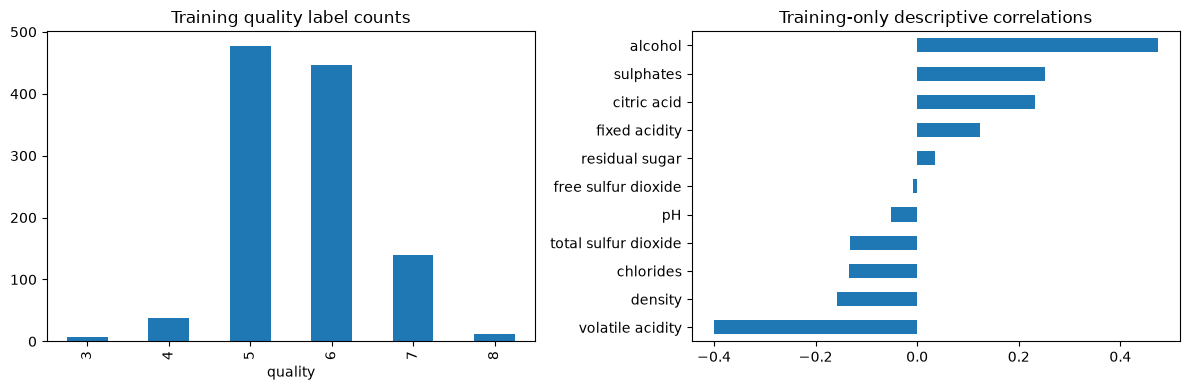

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_train.value_counts().sort_index().plot.bar(ax=axes[0]); axes[0].set_title("Training quality label counts")
pd.concat([X_train,y_train.rename("quality")],axis=1).corr(numeric_only=True)["quality"].drop("quality").sort_values().plot.barh(ax=axes[1]); axes[1].set_title("Training-only descriptive correlations")
plt.tight_layout()

**Observed data-quality record:** the executed notebook reports exact duplicate predictor signatures and verifies repeated signatures agree on quality. Identical signatures are grouped across partitions because the dataset supplies no batch/customer ID; this conservative rule prevents exact-row leakage but cannot establish whether records are repeated measurements or distinct wines.

## 3. Modify

**Purpose and tasks.** Transform and scale within the training workflow; retain predictors available at scoring time; keep the final test partition untouched.

**Phase intent.** Document feature inclusion/exclusion, transformations, split logic, and leakage controls in code.

**Project-specific decision.** Keep all 11 numeric predictors and the original ordinal label. No missing values require imputation. Do not scale for the tree model; preserve exact feature order and use group-disjoint partitions.

**Expected evidence.** A validated feature schema, no null/nonfinite inputs, no partition overlap, and the stated no-scaling decision.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged repeated-vector leakage across random partitions, the ordinal nature of quality scores, and unsupported tail-use claims. The revised split groups identical predictor signatures, uses validation for model selection, reports score-band and tail metrics, and rejects any claim of validated decision support. GPT-5.6 review pass 2 confirmed split integrity and metric consistency, corrected “mean” to “median” baseline, pinned setup versions, and added source archive/member hash assertions.

In [6]:
feature_columns = list(X_train.columns)
assert feature_columns == list(X_valid.columns) == list(X_test.columns)
assert X_train.notna().all().all() and np.isfinite(X_train.to_numpy()).all()
# Random forests split on feature order/rank, so standardization is unnecessary.
X_train_mod, X_valid_mod, X_test_mod = X_train.copy(), X_valid.copy(), X_test.copy()
print("Prepared numeric feature contract",feature_columns,"scaling=none","imputation=none")

Prepared numeric feature contract ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol'] scaling=none imputation=none


## 4. Model

**Purpose and tasks.** Train a transparent baseline and candidate with fixed settings; select using validation performance, not test performance.

**Phase intent.** Fit a transparent baseline and a documented candidate using reproducible settings.

**Project-specific decision.** Compare a median constant baseline, appropriate for MAE, with a 400-tree random forest. Select by validation MAE, refit on train plus validation groups, and evaluate test groups once. Treat ordinal scores as a quasi-continuous recorded-score proxy.

**Expected evidence.** Validation metrics and selection decision, fixed model settings, plus the final refit specification.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged repeated-vector leakage across random partitions, the ordinal nature of quality scores, and unsupported tail-use claims. The revised split groups identical predictor signatures, uses validation for model selection, reports score-band and tail metrics, and rejects any claim of validated decision support. GPT-5.6 review pass 2 confirmed split integrity and metric consistency, corrected “mean” to “median” baseline, pinned setup versions, and added source archive/member hash assertions.

In [7]:
baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
candidate = RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)
candidate.fit(X_train, y_train)
def mae(y0, p): return mean_absolute_error(y0, p)
print("Validation MAE, baseline:", mae(y_valid, baseline.predict(X_valid)))
print("Validation MAE, random forest:", mae(y_valid, candidate.predict(X_valid)))
# Choose the candidate only when validation performance improves over baseline.
winner_name = "random_forest" if mae(y_valid, candidate.predict(X_valid)) < mae(y_valid, baseline.predict(X_valid)) else "median_baseline"
print("Validation-selected specification:",winner_name)
# Refit selected specification on all development groups; keep the group-disjoint test set untouched.
X_dev = pd.concat([X_train,X_valid]); y_dev = pd.concat([y_train,y_valid])
if winner_name == "random_forest": winner = RandomForestRegressor(n_estimators=400,min_samples_leaf=2,random_state=42,n_jobs=-1).fit(X_dev,y_dev)
else: winner = DummyRegressor(strategy="median").fit(X_dev,y_dev)

Validation MAE, baseline: 0.66875
Validation MAE, random forest: 0.48474929935515865
Validation-selected specification: random_forest


## 5. Assess

**Purpose and tasks.** Assess holdout metrics, residuals, and errors by observed score band. Compare against the proposed analytical gates and state whether the model is validated for any decision use.

**Phase intent.** Use metrics aligned to the task, inspect slices and failure cases, and distinguish measured evidence from proposed acceptance criteria.

**Project-specific decision.** Assess the group-disjoint test with MAE/RMSE/R², observed-band signed and absolute errors, rounded prediction distribution, and tail-row recall. The proposed analytical screen requires both the aggregate MAE and tail-capture criteria; no operational workflow has been validated.

**Expected evidence.** One final test metric table, band-level error and bias, tail recall, and the separate analytical-gate decision and resulting use limitation.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged repeated-vector leakage across random partitions, the ordinal nature of quality scores, and unsupported tail-use claims. The revised split groups identical predictor signatures, uses validation for model selection, reports score-band and tail metrics, and rejects any claim of validated decision support. GPT-5.6 review pass 2 confirmed split integrity and metric consistency, corrected “mean” to “median” baseline, pinned setup versions, and added source archive/member hash assertions.

In [8]:
pred = winner.predict(X_test)
metrics = {"MAE": mean_absolute_error(y_test, pred), "RMSE": mean_squared_error(y_test, pred)**0.5, "R2": r2_score(y_test, pred)}
print(metrics)
rounded_pred = np.rint(np.clip(pred,0,10)).astype(int)
band = pd.cut(y_test, bins=[-1, 4, 5, 6, 7, 10], labels=["<=4","5","6","7",">=8"])
errors = pd.DataFrame({"actual": y_test, "prediction": pred, "rounded_prediction":rounded_pred, "absolute_error": np.abs(y_test-pred), "signed_prediction_minus_actual":pred-y_test, "observed_band": band})
display(errors.groupby("observed_band", observed=True).agg(n=("absolute_error","size"),mae=("absolute_error","mean"),mean_signed_error=("signed_prediction_minus_actual","mean")))
true_tail = y_test.isin([3,4,8,9,10]); predicted_tail = pd.Series(rounded_pred,index=y_test.index).isin([3,4,8,9,10])
tail_recall = float((true_tail & predicted_tail).sum()/max(1,true_tail.sum()))
aggregate_gate = metrics["MAE"] <= 0.65; tail_capture_gate = tail_recall >= 0.80
print("rounded prediction labels",sorted(np.unique(rounded_pred)),"tail-row recall",tail_recall,"tail rows",int(true_tail.sum()),"aggregate MAE gate",aggregate_gate,"tail capture gate",tail_capture_gate)
display(pd.crosstab(y_test,rounded_pred,rownames=["observed score"],colnames=["rounded prediction"]))
display(errors.head())

{'MAE': 0.49410048363095244, 'RMSE': 0.6418405278434796, 'R2': 0.3704162654486688}


,n,mae,mean_signed_error
observed_band,,,
<=4,12,1.400403,1.400403
5,136,0.360650,0.311382
6,128,0.451371,-0.279059
7,40,0.701259,-0.701259
>=8,4,1.608277,-1.608277


rounded prediction labels [np.int64(4), np.int64(5), np.int64(6), np.int64(7)] tail-row recall 0.0 tail rows 16 aggregate MAE gate True tail capture gate False


rounded prediction,4,5,6,7
observed score,,,,
3,0,2,0,0
4,0,7,3,0
5,2,107,26,1
6,0,47,70,11
7,0,2,22,16
8,0,0,3,1


,actual,prediction,rounded_prediction,absolute_error,signed_prediction_minus_actual,observed_band
10,5,5.261917,5,0.261917,0.261917,5
18,4,5.204839,5,1.204839,1.204839,<=4
19,6,5.587202,6,0.412798,-0.412798,6
23,5,5.198958,5,0.198958,0.198958,5
37,7,5.701188,6,1.298812,-1.298812,7


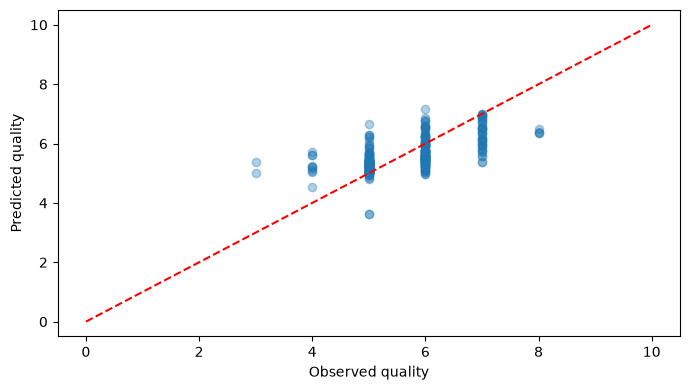

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(errors.actual, errors.prediction, alpha=.35); ax.plot([0,10],[0,10],"r--"); ax.set_xlabel("Observed quality"); ax.set_ylabel("Predicted quality"); plt.tight_layout()

**Evaluation record:** The saved outputs show test MAE 0.494, RMSE 0.642, R² 0.370, and zero recall on 16 extreme-score records. The aggregate gate passes; the tail-capture gate fails. The model is not validated for decision support.

## Research artifact handoff

The notebook saves an experimental model and sample predictions for coursework inspection. Artifact status is `research_only_not_approved`; the tail-capture criterion fails, so the predictions are not a validated triage signal. Input schema and feature order are stored in the artifact. No operational workflow or reduction in sensory review is supported by this analysis.


In [10]:
import joblib
artifact = {"pipeline": winner, "feature_columns": list(X.columns), "target": target, "methodology": "SEMMA", "artifact_version":"1.0", "schema_version":1, "status":"research_only_not_approved", "archive_sha256":archive_sha256, "red_csv_sha256":csv_sha256, "retrieved_utc":retrieved_utc, "training_groups":len(set(groups.iloc[np.concatenate([train_idx,valid_idx])])), "versions":{"python":__import__("sys").version,"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__}}
joblib.dump(artifact, "wine_quality_model.joblib")
sample = X_test.iloc[:20].copy()
sample["predicted_quality"] = artifact["pipeline"].predict(sample)
sample.to_csv("wine_quality_sample_scoring.csv", index=False)
print("Research artifact only: tail-capture gate failed; predictions are not validated for triage or decision support.")

Research artifact only: tail-capture gate failed; predictions are not validated for triage or decision support.


## Limitations, ethics, and next iteration

This is one red-wine subset from a single regional and production context. The ordinal panel score is treated approximately as numeric, and repeated predictor signatures are grouped because no wine/batch identifier is available; the grouping cannot establish whether records are repeated measurements or distinct wines. Extreme scores are sparse, and test recall is zero for those cases. Future work needs broader independent samples, an ordinal-probability comparison, and prospective panel-defined utility. Until then, do not route or deprioritize reviews based on these predictions.


## References

- CRISP-DM: Chapman et al., *CRISP-DM 1.0: Step-by-step data mining guide* (2000), [IBM-hosted PDF](https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf).
- SEMMA: SAS, [Data Mining and SEMMA](https://support.sas.com/documentation/cdl/en/emcs/66392/HTML/default/n0pejm83csbja4n1xueveo2uoujy.htm).
- KDD: Fayyad, Piatetsky-Shapiro, and Smyth (1996), [The KDD Process for Extracting Useful Knowledge](https://doi.org/10.1145/240455.240464).
- Dataset provenance is linked in the charter; consult the original dataset page for the definitive citation and license.